In [55]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## 2.1 Collect the Data

In [62]:
df =  pd.read_csv("/Users/andiiianna/python_decal_fa26/course_assignments/homework9/noisy_curvefit_data.csv")

print(df.shape) 

print(f"There are {df.shape[0]} rows and {df.shape[1]} columns.")

print(df.head())

print(df.tail())

print(f"The column names are {df.columns.tolist()}")

                  

(100, 6)
There are 100 rows and 6 columns.
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850
The column names are ['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


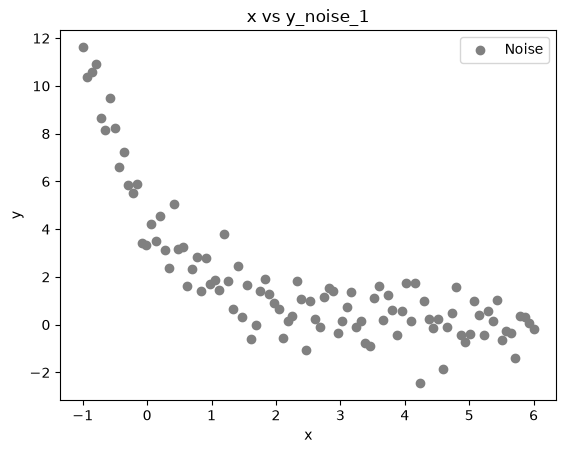

In [57]:
plt.scatter(df["x"],df["y_noise_1"], label = "Noise", color = "gray")
plt.xlabel("x")
plt.ylabel("y")
plt.title("x vs y_noise_1")
plt.legend()

plt.show()


## 2.2 Fit the Data

Fit: y = 4.71 * e^(-0.92 * x)


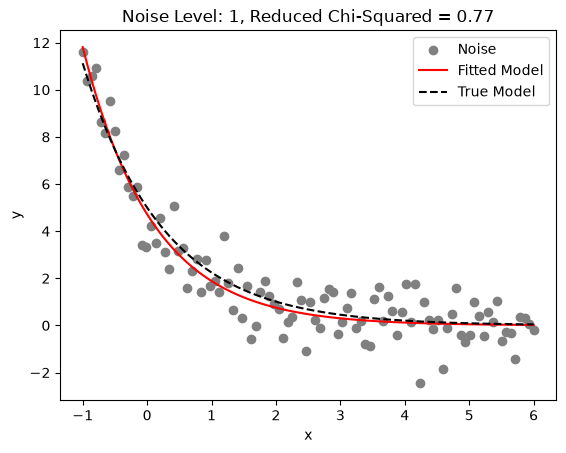

In [58]:
def model(x, A, k):
    return A * np.exp(-k *x)

x = df["x"]
y_noise_1 = df["y_noise_1"]

p0 = [1,1]

popt,pcov = curve_fit (model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x - len(popt))
chi2_reduced = chi2 / dof


plt.scatter(x, y_noise_1, color = "gray", label = "Noise")
plt.plot(x, model(x, A_fit, k_fit), color = "red", label = "Fitted Model")
plt.plot(x, model(x, 5, 0.8), color = "black", label = "True Model", linestyle = "--")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise Level: 1, Reduced Chi-Squared = {chi2_reduced:.2f}")

plt.legend()
plt.show()


## 2.3 Compare Different Noise Levels

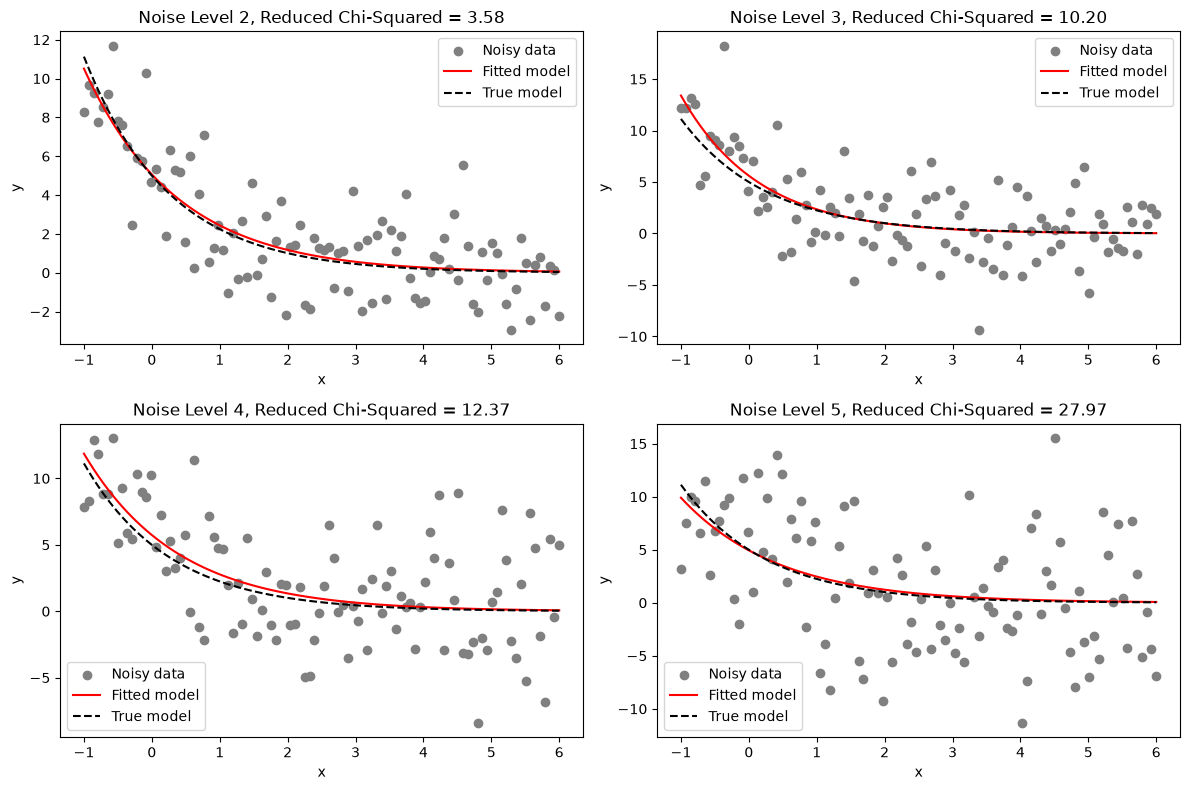

The red and black dotted lines seem to get farther apart as you increase the noise level. Because the data gets mroe scateres makignit harder to fit.
The reduces chi-squared increases as you increase the nosie because the data is more scatters around the fitted line.


In [59]:
def fit_model(x, y):
    p0 = [1,1]
    popt, pcov = curve_fit(model, x, y, p0=p0)

    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x - len(popt))
    chi2_reduced = chi2 / dof

    return popt, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize = (12, 8))

noise_columns = ["y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]

for i, column in enumerate(noise_columns):

    y = df[column]

    popt, chi2_reduced = fit_model(x, y)

    A_fit, k_fit = popt

    ax = axes[i // 2, i % 2]

    ax.scatter(x, y, color="gray", label="Noisy data")

    ax.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted model")

    ax.plot(x, model(x, 5, 0.8), color="black",
            linestyle="--", label="True model")

    ax.set_title(f"Noise Level {i+2}, Reduced Chi-Squared = {chi2_reduced:.2f}")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

print("The red and black dotted lines seem to get farther apart as you increase the noise level. Because the data gets mroe scateres makignit harder to fit.")
print("The reduces chi-squared increases as you increase the nosie because the data is more scatters around the fitted line.")

In [60]:
results_data = []
noise_columns = ['y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']

for col_name in noise_columns:
    noise_level = int(col_name.split('_')[-1])
    popt, chi2_reduced = fit_model(df['x'], df[col_name])
    results_data.append({
        'Noise level': noise_level,
        'A fit': popt[0],
        'k fit': popt[1],
        'Reduced chi-squared': chi2_reduced
    })

df_results = pd.DataFrame(results_data)
print(df_results)

df_results.to_csv("noisy_parameters.csv", index=False)

   Noise level     A fit     k fit  Reduced chi-squared
0            1  4.714814  0.918308             0.774860
1            2  5.063889  0.730396             3.576395
2            3  5.609396  0.870372            10.202003
3            4  5.738727  0.725965            12.374296
4            5  4.943458  0.695012            27.967362
